# Task 5 Very good very nice model

## Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.manifold import Isomap
from sklearn.base import BaseEstimator
from sklearn.linear_model import Ridge

## Auxiliary functions

In [4]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    label = 'SurvivalTime'
    MAX = 500

    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Standard Deviation': np.std(error)
    }
    return metrics
    
def evaluate_model(X, y, c, model, show_cmse=True, show_plot=False):
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv, cMSE_test, model_metrics(y_test, y_pred)

## Data processing

In [5]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)

labeled_df = df.dropna(subset=['SurvivalTime'])
unlabeled_df = df[df['SurvivalTime'].isna()]

X_labeled = labeled_df.drop(columns=['SurvivalTime', 'Censored'])
y_labeled = labeled_df['SurvivalTime']
c_labeled = labeled_df['Censored']

X_unlabeled = unlabeled_df.drop(columns=['SurvivalTime', 'Censored'])
c_unlabeled = unlabeled_df['Censored']

X = pd.concat([X_labeled, X_unlabeled])
c = pd.concat([c_labeled, c_unlabeled])

## Impute the data

In [6]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

## Train Isomap

### Wrapper code

In [7]:
class FrozenTransformer(BaseEstimator):
    def __init__(self, fitted_transformer):
        self.fitted_transformer = fitted_transformer

    def __getattr__(self, name):
        # `fitted_transformer`'s attributes are now accessible
        return getattr(self.fitted_transformer, name)

    def __sklearn_clone__(self):
        return self

    def fit(self, X, y=None):
        # Fitting does not change the state of the estimator
        return self

    def transform(self, X, y=None):
        # transform only transforms the data
        return self.fitted_transformer.transform(X)

    def fit_transform(self, X, y=None):
        # fit_transform only transforms the data
        return self.fitted_transformer.transform(X)

### Standardize features and train the isomap

In [8]:
scaler = StandardScaler()
X_imp_scaled = scaler.fit_transform(X_imp)

iso = Isomap(n_components=4)
iso.fit(X_imp_scaled)

Isomap(n_components=4)

## Find best K for KNN regression

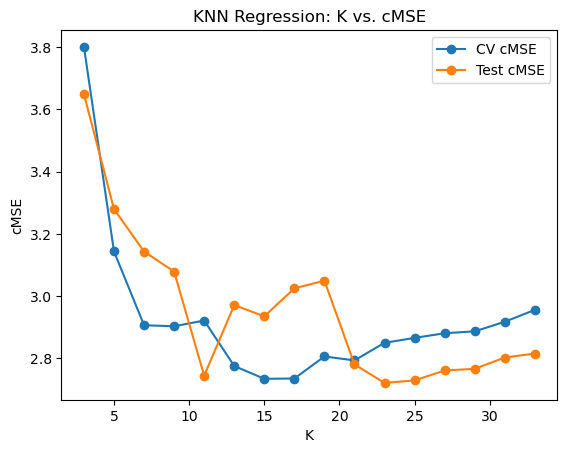

In [10]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33]
knn_scores = []
knn_test_scores = []

for k in k_values:
    iso = Isomap(n_components=4)
    iso.fit(X_imp_scaled)
    
    ft_knn_model = make_pipeline(
    knn_imputer, 
    scaler, 
    FrozenTransformer(iso), 
    KNeighborsRegressor(n_neighbors=k))
    
    _, cv_score, test_score, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_knn_model, show_cmse=False)
    
    knn_scores.append(cv_score)
    knn_test_scores.append(test_score)

plt.plot(k_values, knn_scores, marker='o', label="CV cMSE")
plt.plot(k_values, knn_test_scores, marker='o', label="Test cMSE")
plt.xlabel("K")
plt.ylabel("cMSE")
plt.legend()
plt.title("KNN Regression: K vs. cMSE")
plt.show()

## Find best Alpha for Ridge

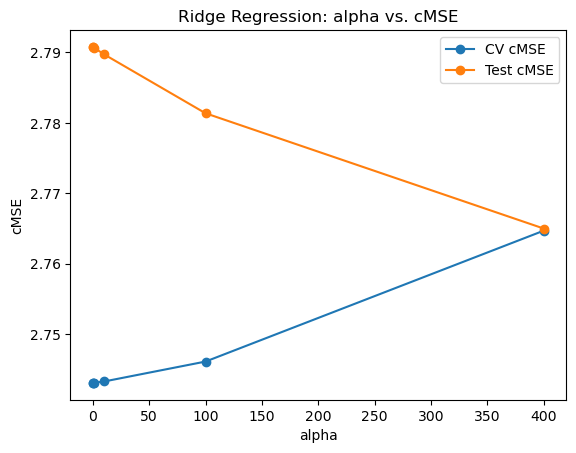

In [12]:
alpha_values = [0.01, 0.1, 1, 10, 100, 400]
alpha_scores = []
alpha_test_scores = []

for alpha in alpha_values:
    iso = Isomap(n_components=4)
    iso.fit(X_imp_scaled)

    ft_l2_model = make_pipeline(
        knn_imputer,
        scaler,
        FrozenTransformer(iso),
        Ridge(alpha=alpha))

    _, cv_score, test_score, _ = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_l2_model, show_cmse=False)

    alpha_scores.append(cv_score)
    alpha_test_scores.append(test_score)

plt.plot(alpha_values, alpha_scores, marker='o', label="CV cMSE")
plt.plot(alpha_values, alpha_test_scores, marker='o', label="Test cMSE")
plt.xlabel("alpha")
plt.ylabel("cMSE")
plt.title("Ridge Regression: alpha vs. cMSE")
plt.legend()
plt.show()

## Stacking regressor

In [9]:
base_models = [
    ('rf', RandomForestRegressor(random_state=30, max_depth=1, max_features=1, n_estimators=500)),
    ('cat', CatBoostRegressor(random_state=30, max_depth=3, learning_rate=0.01, n_estimators=100, silent=True)),
    ('xgb', XGBRegressor(random_state=30, max_depth=1, learning_rate=0.05, n_estimators=300)),
    ('knn', KNeighborsRegressor(n_neighbors=21)),
    ('l2', Ridge(alpha=100.0))
]

model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0),
    cv=5
)

ft_stacking_model = make_pipeline(
    knn_imputer,
    scaler,
    FrozenTransformer(iso),
    model
)

ft_stacking_imp_model, _, _, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_stacking_model)

CV cMSE: 2.7614975320122213
Test cMSE: 2.8267846059691846


## Submission

In [33]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)

In [34]:
imputer_knn = KNNImputer(n_neighbors=19)
X_imp_knn = imputer_knn.fit_transform(X_kaggle_df)

In [41]:
y_stacking_imp_knn_pred = ft_stacking_imp_model.predict(X_imp_knn)
save_predictions(y_stacking_imp_knn_pred, './submissions/optional-submission-08.csv')